In [27]:
import sys
from pathlib import Path

current_dir = Path.cwd()
proj_dir = current_dir.parent.parent.resolve() # get project root directory

print(f"Project directory set to: {proj_dir}")

# Add the project root to the system path to import local modules
sys.path.append(str(proj_dir / "python"))

Project directory set to: E:\Admin\Documents\dermascan


In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import onnx
import onnxruntime

from dataset_manager import DatasetManager
import cv2

# Exporting the trained UNet Model for Lesion Cutout

## Defining the UNet

In [29]:
# Model Definition
class UNet(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        self.n_channels = n_channels
        self.n_classes = n_classes

        # Contracting path (encoder)
        self.conv1 = nn.Conv2d(self.n_channels, 64, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(256, 512, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(512, 1024, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Expansive path (decoder)
        self.upconv1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv6 = nn.Conv2d(1024, 512, kernel_size=3, padding=1)
        self.upconv2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv7 = nn.Conv2d(512, 256, kernel_size=3, padding=1)
        self.upconv3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv8 = nn.Conv2d(256, 128, kernel_size=3, padding=1)
        self.upconv4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv9 = nn.Conv2d(128, 64, kernel_size=3, padding=1)
        self.conv10 = nn.Conv2d(64, self.n_classes, kernel_size=1)

    def forward(self, x):
        # Contracting path (encoder)
        x1 = F.relu(self.conv1(x))
        x2 = F.relu(self.conv2(self.pool(x1)))
        x3 = F.relu(self.conv3(self.pool(x2)))
        x4 = F.relu(self.conv4(self.pool(x3)))
        x5 = F.relu(self.conv5(self.pool(x4)))

        # Expansive path (decoder)
        x6 = F.relu(self.upconv1(x5))
        x6 = torch.cat([x4, x6], dim=1)
        x6 = F.relu(self.conv6(x6))
        x7 = F.relu(self.upconv2(x6))
        x7 = torch.cat([x3, x7], dim=1)
        x7 = F.relu(self.conv7(x7))
        x8 = F.relu(self.upconv3(x7))
        x8 = torch.cat([x2, x8], dim=1)
        x8 = F.relu(self.conv8(x8))
        x9 = F.relu(self.upconv4(x8))
        x9 = torch.cat([x1, x9], dim=1)
        x9 = F.relu(self.conv9(x9))
        x10 = self.conv10(x9)

        return x10

## Exporting the Model

In [30]:
# Load a sample input tensor
dataset_manager = DatasetManager(
    data_dir=str(proj_dir / "data")
)

dataset_manager.load_cleaned_metadata()

# sample_row = dataset_manager.df.sample(1).iloc[0]
sample_row = dataset_manager.df.loc[dataset_manager.df["image_id"] == Path("ISIC_0024308").stem].iloc[0]
sample_img = cv2.imread(str(proj_dir / "data" / sample_row['image_path']))
print(sample_img)
sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
sample_img = cv2.resize(sample_img, (256, 256), interpolation=cv2.INTER_NEAREST)


# Convert to tensor
img_tensor = torch.from_numpy(sample_img).float() / 255.0
img_tensor = img_tensor.permute(2, 0, 1).unsqueeze(0)

# print(img_tensor.shape)
print(img_tensor.numpy(force=True))

[[[178 169 242]
  [182 173 246]
  [182 173 246]
  ...
  [181 169 245]
  [183 171 247]
  [183 170 248]]

 [[179 172 247]
  [183 173 249]
  [183 172 245]
  ...
  [181 169 245]
  [178 167 247]
  [183 170 248]]

 [[179 172 247]
  [181 172 245]
  [181 172 245]
  ...
  [181 168 242]
  [180 164 247]
  [184 170 248]]

 ...

 [[160 170 234]
  [162 169 232]
  [167 172 235]
  ...
  [156 144 216]
  [155 140 214]
  [153 138 212]]

 [[162 172 236]
  [166 172 237]
  [168 169 237]
  ...
  [157 146 216]
  [157 143 215]
  [156 142 213]]

 [[165 174 237]
  [169 174 237]
  [169 171 236]
  ...
  [154 146 216]
  [155 144 216]
  [156 145 217]]]
[[[[0.9490196  0.9647059  0.96862745 ... 0.9647059  0.9764706
    0.9607843 ]
   [0.96862745 0.9607843  0.9647059  ... 0.9647059  0.9607843
    0.9607843 ]
   [0.95686275 0.9647059  0.9607843  ... 0.9607843  0.9764706
    0.9647059 ]
   ...
   [0.91764706 0.90588236 0.9490196  ... 0.8509804  0.84705883
    0.84313726]
   [0.92156863 0.92941177 0.9490196  ... 0.8470588

In [ ]:
torch_model = UNet(n_channels=3, n_classes=1)
torch_model.load_state_dict(torch.load('../abcd_algorithms/enhanced_lesion_cutout/checkpointN25_.pth.tar')['state_dict'])
torch_model.eval()

example_inputs = (img_tensor,)
onnx_model = torch.onnx.export(
    torch_model, 
    example_inputs, 
    "unet1.onnx", 
    dynamo=False # NEEDS TO BE FALSE OTHERWISE INFERENCE IN FLUTTER WILL RESULT IN LOGITS BETWEEN -0.002 AND 0.002 INSTEAD OF THE EXPECTED -10 TO 10
    )

onnx_model = onnx.load("unet1.onnx")
onnx.checker.check_model(onnx_model)

C:\Users\Admin\AppData\Local\Temp\ipykernel_30316\901974308.py:6: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter will be the default. To switch now, set dynamo=True in torch.onnx.export. This new exporter supports features like exporting LLMs with DynamicCache. We encourage you to try it and share feedback to help improve the experience. Learn more about the new export logic: https://pytorch.org/docs/stable/onnx_dynamo.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html.
  onnx_model = torch.onnx.export(torch_model, example_inputs, "unet1.onnx", dynamo=False)


## Testing the exported model with the ONNX Runtime

In [23]:
onnx_inputs = [tensor.numpy(force=True) for tensor in example_inputs]


ort_session = onnxruntime.InferenceSession(
    "./unet.onnx", providers=["CPUExecutionProvider"]
)

onnxruntime_input = {input_arg.name: input_value for input_arg, input_value in zip(ort_session.get_inputs(), onnx_inputs)}

# ONNX Runtime returns a list of outputs
onnxruntime_outputs = ort_session.run(None, onnxruntime_input)[0]
print(f"ONNX logits shape:\n{onnxruntime_outputs.shape}")
print(f"ONNX logits:\n{onnxruntime_outputs}")

ONNX logits shape:
(1, 1, 256, 256)
ONNX logits:
[[[[-3.5296009 -4.159746  -3.9260297 ... -4.4833946 -4.7307854
    -3.9805112]
   [-4.342052  -4.7364388 -4.4124694 ... -5.231936  -5.7012615
    -5.141314 ]
   [-3.9026797 -4.0604324 -3.7080495 ... -4.8224483 -5.3565154
    -4.973429 ]
   ...
   [-4.0046268 -4.347509  -3.835388  ... -2.2430189 -2.9084647
    -3.4643245]
   [-3.947581  -4.3479605 -4.2214093 ... -2.8262622 -3.4602726
    -3.595403 ]
   [-3.5700128 -4.056303  -3.905345  ... -3.0054843 -3.3689468
    -3.1285799]]]]


In [ ]:
torch_outputs = torch_model(*example_inputs)

assert len(torch_outputs) == len(onnxruntime_outputs)
for torch_output, onnxruntime_output in zip(torch_outputs, onnxruntime_outputs):
    torch.testing.assert_close(torch_output, torch.tensor(onnxruntime_output))

Distance between PyTorch and ONNX Runtime outputs: 0.00020661402959376574


## Visualizing ONNX Output

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from abcd_algorithms.mask_utils import boundary_extraction

# Helper methods for cleaning the generated mask
def to_binary_mask(mask, threshold=0.5, use_sigmoid=True):
    """
    Convert model output to a binary uint8 mask (0 or 255).
    """
    mask = mask.astype(np.float32)

    if use_sigmoid:
        mask = 1.0 / (1.0 + np.exp(-mask))

    binary = (mask >= threshold).astype(np.uint8) * 255
    return binary

def get_largest_connected_area(binary_mask):
    """
    Keep only the largest connected component in a binary mask.
    """
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask, connectivity=8)

    # No foreground found
    if num_labels <= 1:
        return np.zeros_like(binary_mask, dtype=np.uint8)

    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    largest = (labels == largest_label).astype(np.uint8) * 255
    return largest


def smooth_mask_edges(mask, morph_kernel_size=7, blur_kernel_size=9):
    """
    Smooth contour using morphology + Gaussian blur.
    Returns a cleaned binary mask (0 or 255).
    """
    if blur_kernel_size % 2 == 0:
        blur_kernel_size += 1  # Gaussian kernel must be odd

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (morph_kernel_size, morph_kernel_size))

    cleaned = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, kernel)

    blurred = cv2.GaussianBlur(cleaned, (blur_kernel_size, blur_kernel_size), sigmaX=0)
    smoothed = ((blurred > 127).astype(np.uint8) * 255)

    return smoothed

def fill_holes_in_mask(mask):
    """
    Fill internal holes in a binary mask (0 or 255).
    """
    mask_u8 = (mask > 0).astype(np.uint8) * 255

    h, w = mask_u8.shape[:2]
    flood = mask_u8.copy()
    flood_fill_buffer = np.zeros((h + 2, w + 2), dtype=np.uint8)

    cv2.floodFill(flood, flood_fill_buffer, seedPoint=(0, 0), newVal=255)

    holes = cv2.bitwise_not(flood)
    filled = cv2.bitwise_or(mask_u8, holes)
    return filled

def resize_mask_to_original(mask, original_size):
    """
    Resize the mask back to the original image size.
    """
    return cv2.resize(mask, (original_size[1], original_size[0]), interpolation=cv2.INTER_NEAREST)

def clean_generated_mask(
    raw_mask,
    threshold=0.5,
    use_sigmoid=True,
    morph_kernel_size=7,
    blur_kernel_size=9,
    resize_to_shape = (256, 256)
):
    """
    Full cleanup pipeline.
    """
    binary = to_binary_mask(raw_mask, threshold=threshold, use_sigmoid=use_sigmoid)
    largest = get_largest_connected_area(binary)
    filled = fill_holes_in_mask(largest)
    resized = resize_mask_to_original(filled, original_size=resize_to_shape)
    smoothed = smooth_mask_edges(
        resized,
        morph_kernel_size=morph_kernel_size,
        blur_kernel_size=blur_kernel_size
    )
    return smoothed

In [38]:
# The output from ONNX runtime has shape (1, 1, 256, 256). Squeeze it to (256, 256)
onnx_generated_mask = np.squeeze(onnxruntime_outputs)
pytorch_generated_mask = np.squeeze(onnxruntime_outputs)

onnx_generated_mask_stacked = np.stack((onnx_generated_mask,)*3, axis=-1) # shape (256, 256, 3)
pytorch_generated_mask_stacked = np.stack((pytorch_generated_mask,)*3, axis=-1) # shape (256, 256, 3)

# Apply cleanup 
onnx_cleaned_mask = clean_generated_mask( 
    onnx_generated_mask,
    threshold=0.8,
    use_sigmoid=True,
    morph_kernel_size=7,
    blur_kernel_size=9,
    resize_to_shape=(sample_img.shape[0], sample_img.shape[1])
)
pytorch_cleaned_mask = clean_generated_mask( 
    pytorch_generated_mask,
    threshold=0.8,
    use_sigmoid=True,
    morph_kernel_size=7,
    blur_kernel_size=9,
    resize_to_shape=(sample_img.shape[0], sample_img.shape[1])
)

onnx_cleaned_mask_stacked = np.stack((onnx_cleaned_mask,) * 3, axis=-1) # shape (256, 256, 3)
pytorch_cleaned_mask_stacked = np.stack((pytorch_cleaned_mask,) * 3, axis=-1) # shape (256, 256, 3)


# Overlay outline on original image
onnx_outline = boundary_extraction(onnx_cleaned_mask)
pytorch_outline = boundary_extraction(pytorch_cleaned_mask)

onnx_overlay_outline = sample_img.copy()
onnx_overlay_outline[onnx_outline > 0] = [255, 0, 0]

pytorch_overlay_outline = sample_img.copy()
pytorch_overlay_outline[pytorch_outline > 0] = [255, 0, 0]

# Calculate the overlap percentage between the ONNX outline and the PyTorch outline
overlap = np.logical_and(onnx_outline > 0, pytorch_outline > 0).sum()
total_pytorch_outline = (pytorch_outline > 0).sum()
overlap_percentage = (overlap / total_pytorch_outline) * 100 if total_pytorch_outline > 0 else 0
print(f"Overlap between ONNX and PyTorch outlines: {overlap_percentage:.2f}%")

Overlap between ONNX and PyTorch outlines: 100.00%


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-7.416616..8.888488].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-7.416616..8.888488].


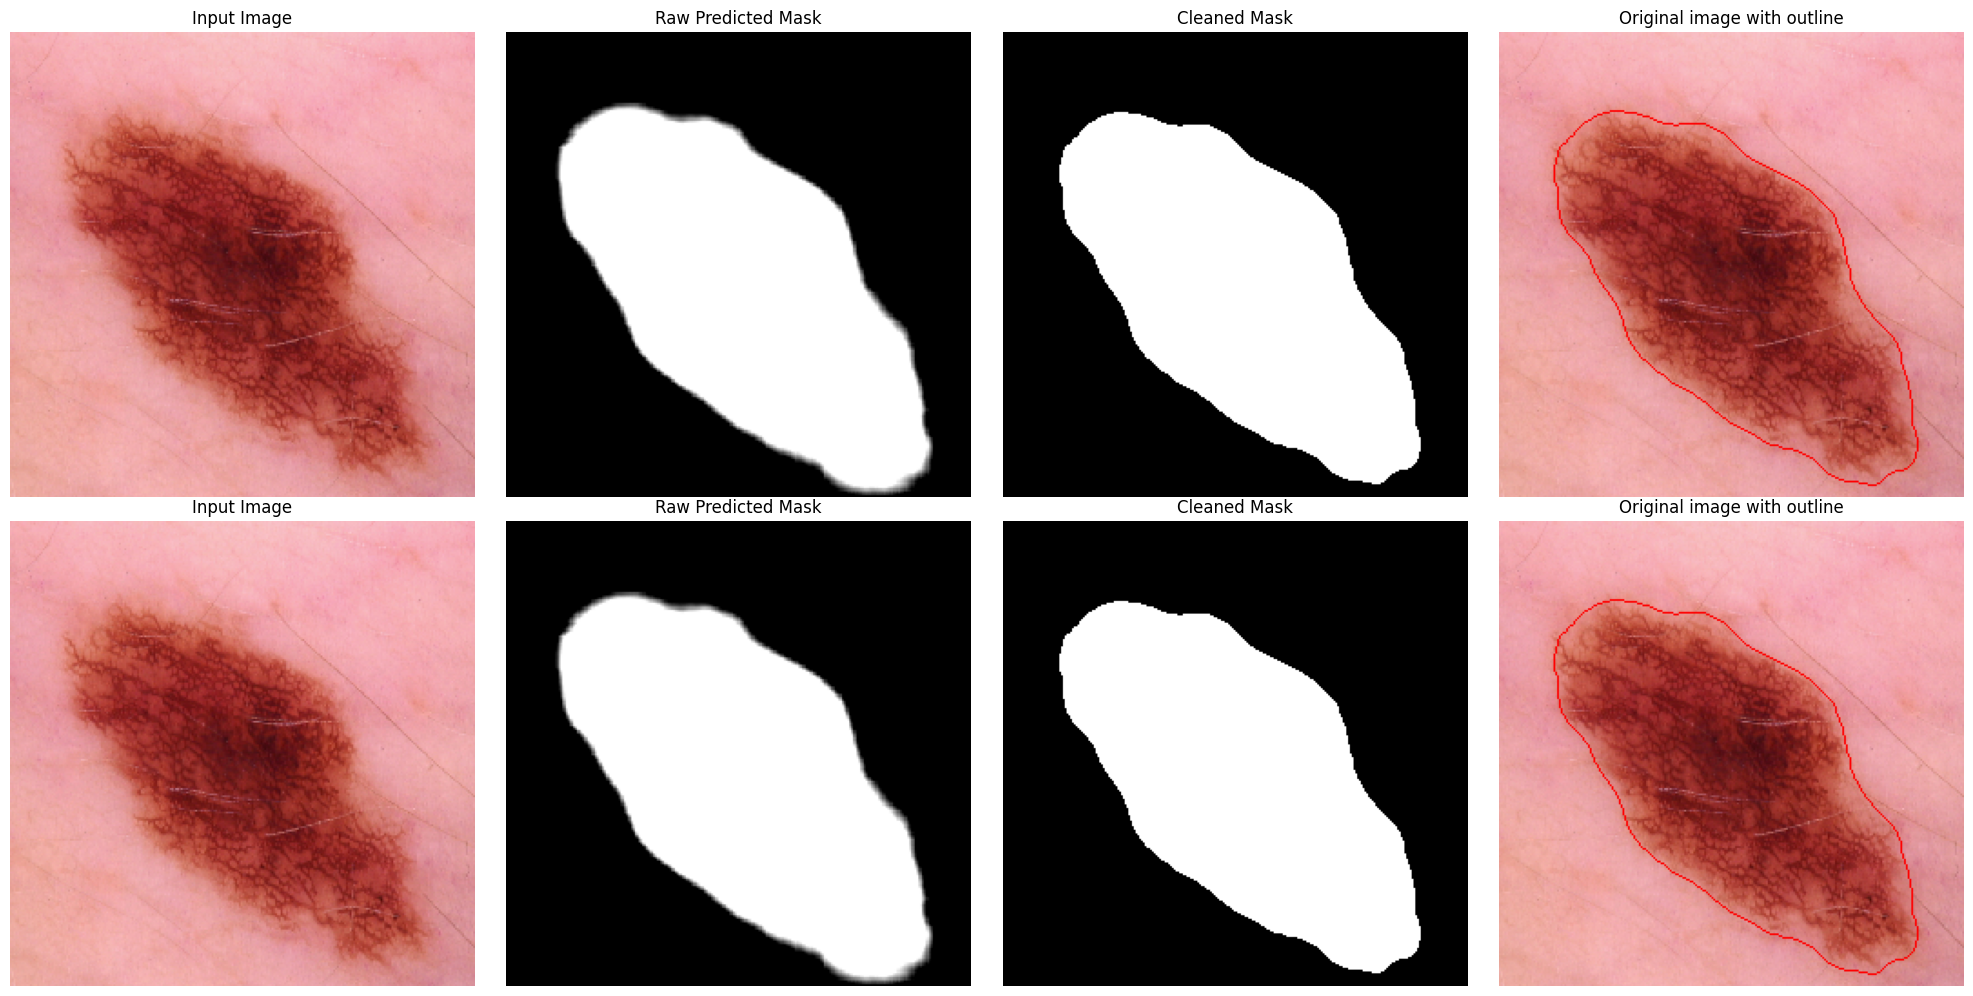

In [ ]:
# Preview
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes[0, 0].imshow(sample_img)
axes[0, 0].set_title("Input Image")
axes[0, 0].axis("off")

axes[0, 1].imshow(onnx_generated_mask_stacked, cmap="gray")
axes[0, 1].set_title("Raw Predicted Mask")
axes[0, 1].axis("off")

axes[0, 2].imshow(onnx_cleaned_mask_stacked)
axes[0, 2].set_title("Cleaned Mask")
axes[0, 2].axis("off")

axes[0, 3].imshow(onnx_overlay_outline)
axes[0, 3].set_title("Original image with outline")
axes[0, 3].axis('off')

axes[1, 0].imshow(sample_img)
axes[1, 0].set_title("Input Image")
axes[1, 0].axis("off")

axes[1, 1].imshow(pytorch_generated_mask_stacked, cmap="gray")
axes[1, 1].set_title("Raw Predicted Mask")
axes[1, 1].axis("off")

axes[1, 2].imshow(pytorch_cleaned_mask_stacked)
axes[1, 2].set_title("Cleaned Mask")
axes[1, 2].axis("off")

axes[1, 3].imshow(pytorch_overlay_outline)
axes[1, 3].set_title("Original image with outline")
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()